# Data Visualization with Python: A Comprehensive Guide to Matplotlib and Seaborn

## Overview
Data visualization is an essential discipline in modern data science. It transforms abstract numerical figures into intuitive graphical representations, enabling analysts, stakeholders, and decision-makers to rapidly uncover hidden patterns, detect anomalies, evaluate distributions, and communicate findings with clarity.

This guide provides an end-to-end exploration of Python's two foundational visualization libraries:
1. **Matplotlib**: The low-level, highly customizable workhorse of Python plotting.
2. **Seaborn**: The high-level statistical visualization library built on top of Matplotlib.

Each section includes theoretical background, structural anatomy, practical use cases, and fully executable code examples.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set aesthetic defaults
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", palette="muted")

print("Visualization libraries imported successfully.")

Visualization libraries imported successfully.


---
# Section 1: Matplotlib Deep Dive

### 1.1 Architecture and Philosophy
Matplotlib was created by John D. Hunter in 2002 to emulate MATLAB-like plotting capabilities in Python. Its architecture is organized into a clear hierarchy:

1. **Figure**: The top-level container that holds all plot elements, axes, titles, subtitles, and colorbars.
2. **Axes**: The actual canvas or sub-region where data is plotted. A figure can contain multiple axes (subplots).
3. **Axis**: The scale, ticks, tick labels, and axis limits (x-axis and y-axis).
4. **Artists**: Everything visible on the figure (lines, shapes, text, legends, collections).
5. **Pyplot (`matplotlib.pyplot`)**: A procedural, state-machine interface that simplifies figure and axes manipulation.

---
### 1.2 Line Plot
**Use Case:** Tracking continuous variables and chronological trends over time, such as revenue trajectories, stock prices, or sensor readings.

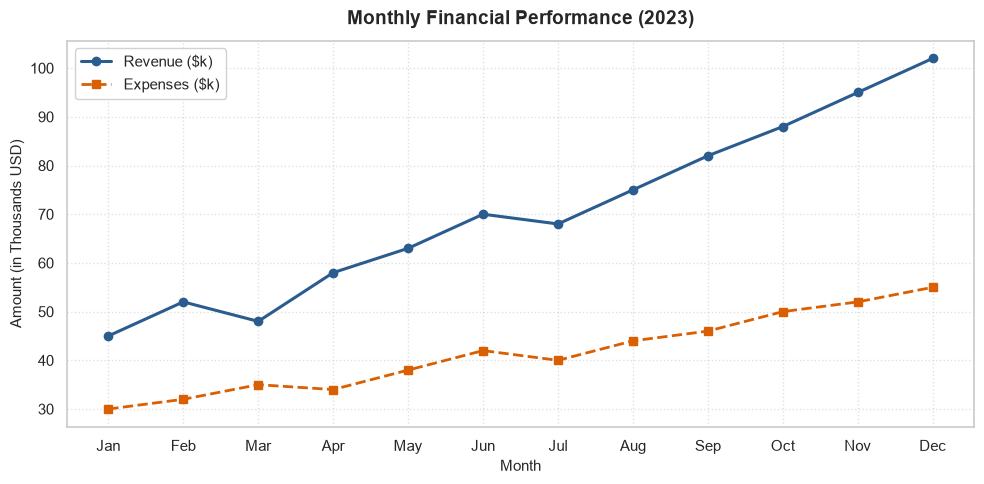

In [2]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
revenue = [45, 52, 48, 58, 63, 70, 68, 75, 82, 88, 95, 102]
expenses = [30, 32, 35, 34, 38, 42, 40, 44, 46, 50, 52, 55]

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
ax.plot(months, revenue, marker='o', linewidth=2.2, color='#2b5c8f', label='Revenue ($k)')
ax.plot(months, expenses, marker='s', linewidth=2, linestyle='--', color='#d95f02', label='Expenses ($k)')

ax.set_title('Monthly Financial Performance (2023)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Amount (in Thousands USD)', fontsize=11)
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---
### 1.3 Bar Chart (Grouped)
**Use Case:** Comparing categorical variables across groups or time periods, such as annual product category volume.

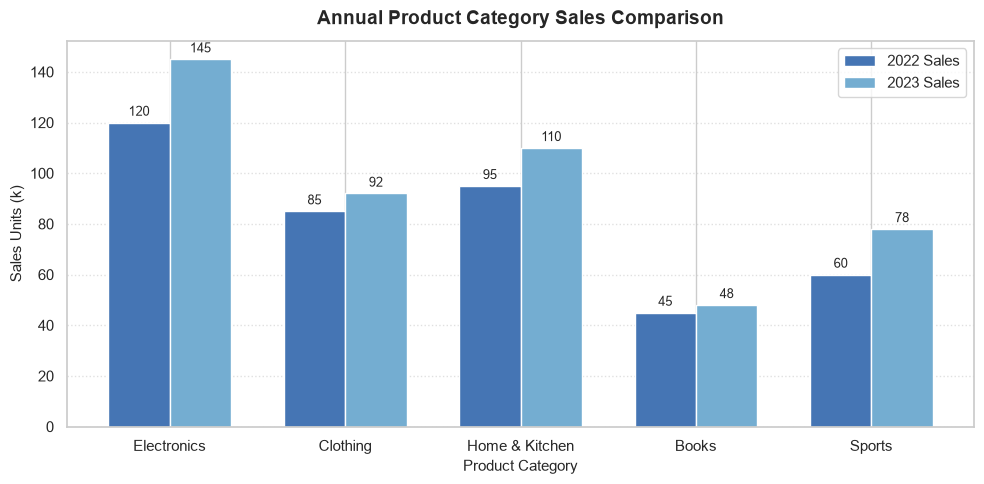

In [3]:
categories = ['Electronics', 'Clothing', 'Home & Kitchen', 'Books', 'Sports']
sales_2022 = [120, 85, 95, 45, 60]
sales_2023 = [145, 92, 110, 48, 78]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
rects1 = ax.bar(x - width/2, sales_2022, width, label='2022 Sales', color='#4575b4')
rects2 = ax.bar(x + width/2, sales_2023, width, label='2023 Sales', color='#74add1')

ax.set_title('Annual Product Category Sales Comparison', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Product Category', fontsize=11)
ax.set_ylabel('Sales Units (k)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend(frameon=True)
ax.bar_label(rects1, padding=3, fontsize=9)
ax.bar_label(rects2, padding=3, fontsize=9)
ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---
### 1.4 Scatter Plot with Continuous Color & Sizing
**Use Case:** Examining the correlation and relationship between two continuous numerical variables, with auxiliary dimensions encoded via marker size and color intensity.

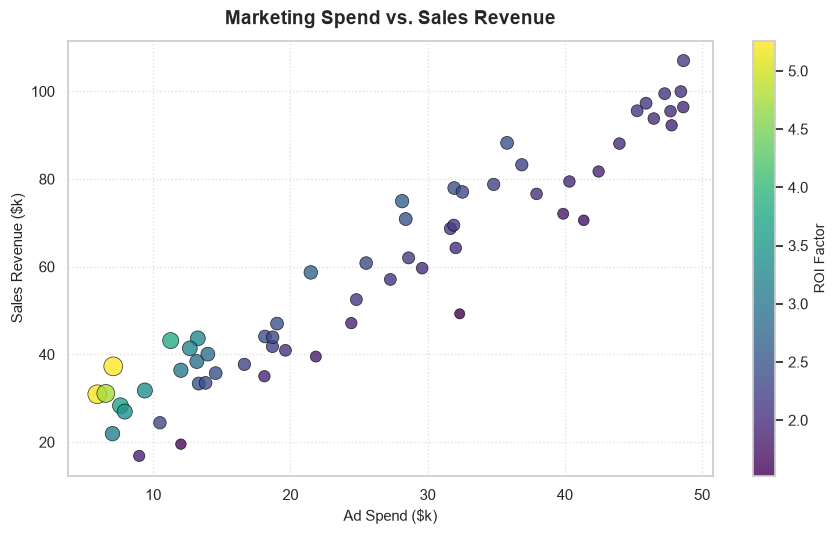

In [4]:
np.random.seed(42)
ad_spend = np.random.uniform(5, 50, 60)
sales = 12 + 1.8 * ad_spend + np.random.normal(0, 8, 60)
roi = sales / ad_spend

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=100)
scatter = ax.scatter(ad_spend, sales, c=roi, cmap='viridis', s=roi*35, alpha=0.8, edgecolors='black', linewidth=0.5)
cbar = plt.colorbar(scatter)
cbar.set_label('ROI Factor', fontsize=10)

ax.set_title('Marketing Spend vs. Sales Revenue', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Ad Spend ($k)', fontsize=11)
ax.set_ylabel('Sales Revenue ($k)', fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---
### 1.5 Histogram with Benchmark Threshold
**Use Case:** Inspecting the frequency distribution, skewness, spread, and central tendency of a continuous variable.

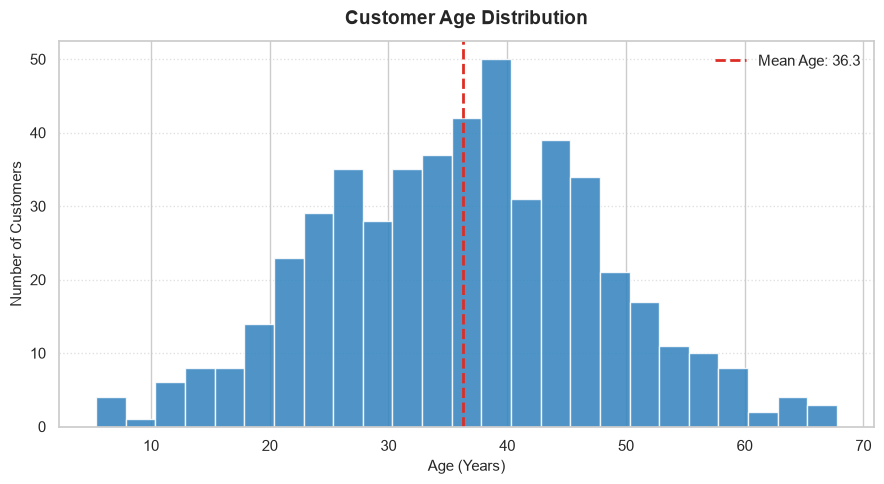

In [5]:
np.random.seed(101)
customer_ages = np.random.normal(36, 11, 500)

fig, ax = plt.subplots(figsize=(9, 5), dpi=100)
n, bins, patches = ax.hist(customer_ages, bins=25, color='#3182bd', edgecolor='white', alpha=0.85)
ax.axvline(np.mean(customer_ages), color='#de2d26', linestyle='dashed', linewidth=2, label=f'Mean Age: {np.mean(customer_ages):.1f}')

ax.set_title('Customer Age Distribution', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Age (Years)', fontsize=11)
ax.set_ylabel('Number of Customers', fontsize=11)
ax.legend()
ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---
### 1.6 Pie Chart (Proportions & Composition)
**Use Case:** Displaying part-to-whole proportions for categorical attributes with a small number of categories (<= 5).

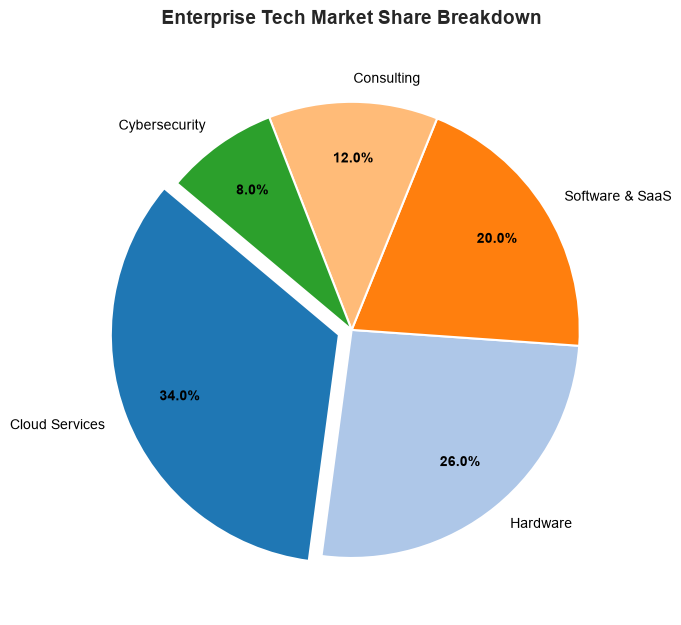

In [6]:
market_segments = ['Cloud Services', 'Hardware', 'Software & SaaS', 'Consulting', 'Cybersecurity']
market_share = [34, 26, 20, 12, 8]
colors = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#2ca02c']
explode = (0.06, 0, 0, 0, 0)

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
wedges, texts, autotexts = ax.pie(
    market_share, explode=explode, labels=market_segments, colors=colors,
    autopct='%1.1f%%', startangle=140, pctdistance=0.75,
    textprops=dict(color='black', fontsize=10),
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_weight('bold')

ax.set_title('Enterprise Tech Market Share Breakdown', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

---
### 1.7 Multi-Panel Layouts (Subplots)
**Use Case:** Creating structured analytical dashboards displaying multiple perspectives within a single composite figure.

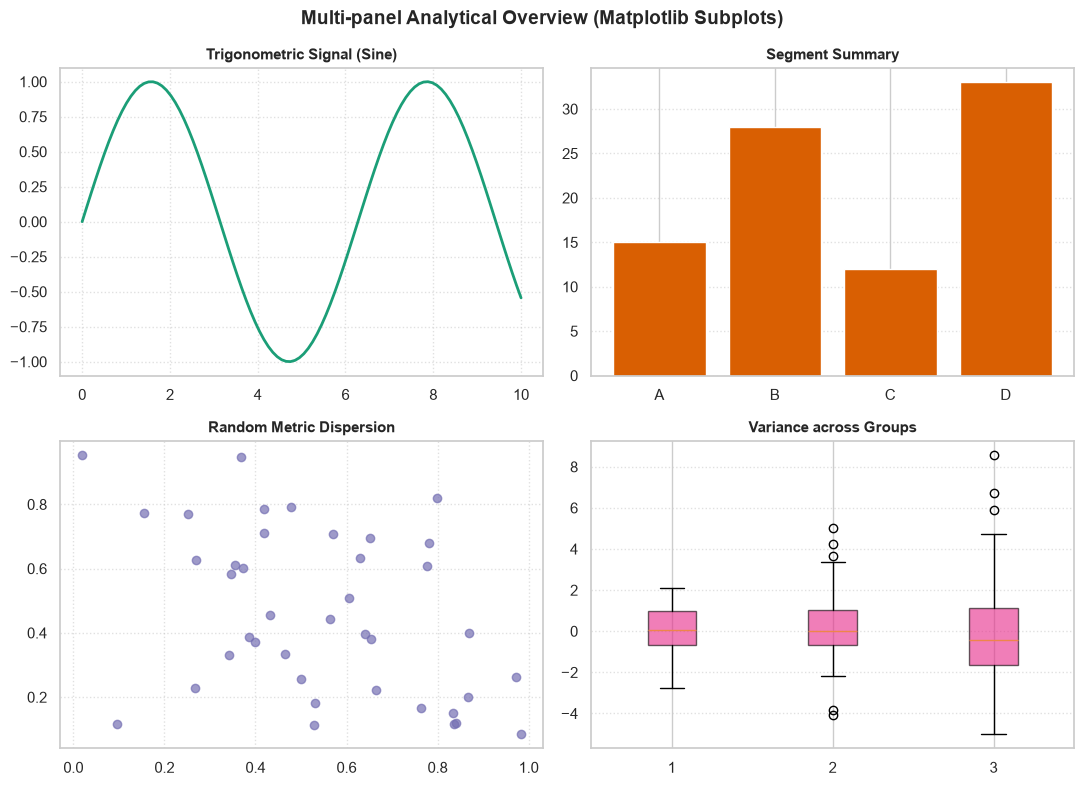

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8), dpi=100)
x_vals = np.linspace(0, 10, 100)

axs[0, 0].plot(x_vals, np.sin(x_vals), color='#1b9e77', linewidth=2)
axs[0, 0].set_title('Trigonometric Signal (Sine)', fontsize=11, fontweight='bold')
axs[0, 0].grid(True, linestyle=':', alpha=0.6)

axs[0, 1].bar(['A', 'B', 'C', 'D'], [15, 28, 12, 33], color='#d95f02')
axs[0, 1].set_title('Segment Summary', fontsize=11, fontweight='bold')
axs[0, 1].grid(axis='y', linestyle=':', alpha=0.6)

axs[1, 0].scatter(np.random.rand(40), np.random.rand(40), color='#7570b3', alpha=0.7)
axs[1, 0].set_title('Random Metric Dispersion', fontsize=11, fontweight='bold')
axs[1, 0].grid(True, linestyle=':', alpha=0.6)

axs[1, 1].boxplot([np.random.normal(0, std, 50) for std in range(1, 4)], patch_artist=True,
                  boxprops=dict(facecolor='#e7298a', alpha=0.6))
axs[1, 1].set_title('Variance across Groups', fontsize=11, fontweight='bold')
axs[1, 1].grid(axis='y', linestyle=':', alpha=0.6)

plt.suptitle('Multi-panel Analytical Overview (Matplotlib Subplots)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
# Section 2: Seaborn Deep Dive

### 2.1 Architecture and Philosophy
Seaborn is a high-level statistical data visualization library built directly on top of Matplotlib and tightly integrated with Pandas DataFrames. 

Key advantages of Seaborn:
* **DataFrame-Centric API**: Directly accepts column names as arguments (`x='total_bill'`, `y='tip'`, `hue='time'`).
* **Automated Statistical Aggregation**: Automatically computes confidence intervals, descriptive distributions, and regression fits.
* **Refined Default Aesthetics**: Preconfigured color palettes and elegant styles that enhance visual clarity without requiring manual configuration.
* **Multi-Plot Faceting**: Provides unified figures like `pairplot` and `FacetGrid` for exploratory multivariate exploration.

We will use the built-in **`tips`** dataset to demonstrate Seaborn's capabilities.

In [8]:
tips = sns.load_dataset('tips')
print("Sample of tips dataset:")
display(tips.head())

Sample of tips dataset:


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


---
### 2.2 Relational Scatter Plot with Faceted Semantics
**Use Case:** Multivariate exploratory analysis mapping numerical correlation while slicing by categorical variables using hue, style, and size.

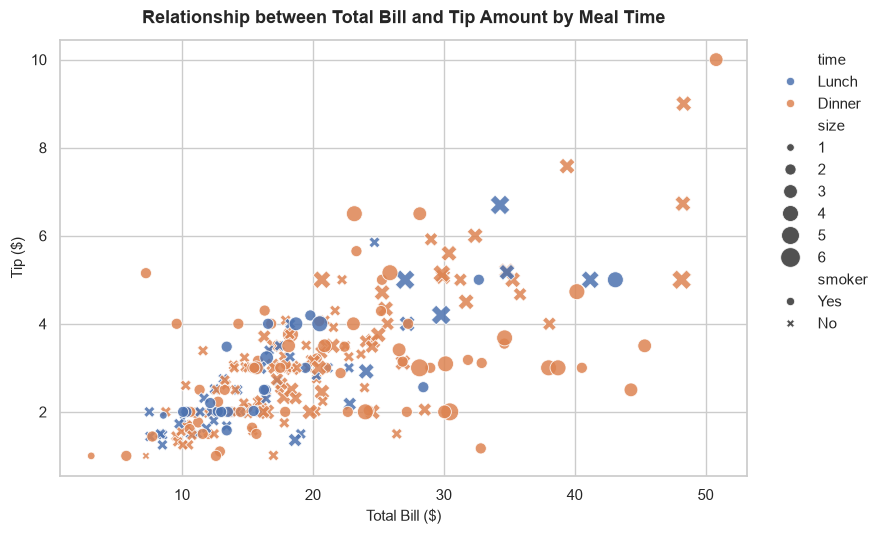

In [9]:
plt.figure(figsize=(9, 5.5), dpi=100)
sns.scatterplot(
    data=tips, x='total_bill', y='tip', hue='time',
    size='size', sizes=(30, 200), style='smoker', palette='deep', alpha=0.85
)
plt.title('Relationship between Total Bill and Tip Amount by Meal Time', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Total Bill ($)', fontsize=11)
plt.ylabel('Tip ($)', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
### 2.3 Categorical Distributions: Box Plot & Violin Plot
**Use Case:** Comparing five-number summaries (median, quartiles, outliers) and full probability density shapes across discrete categories.

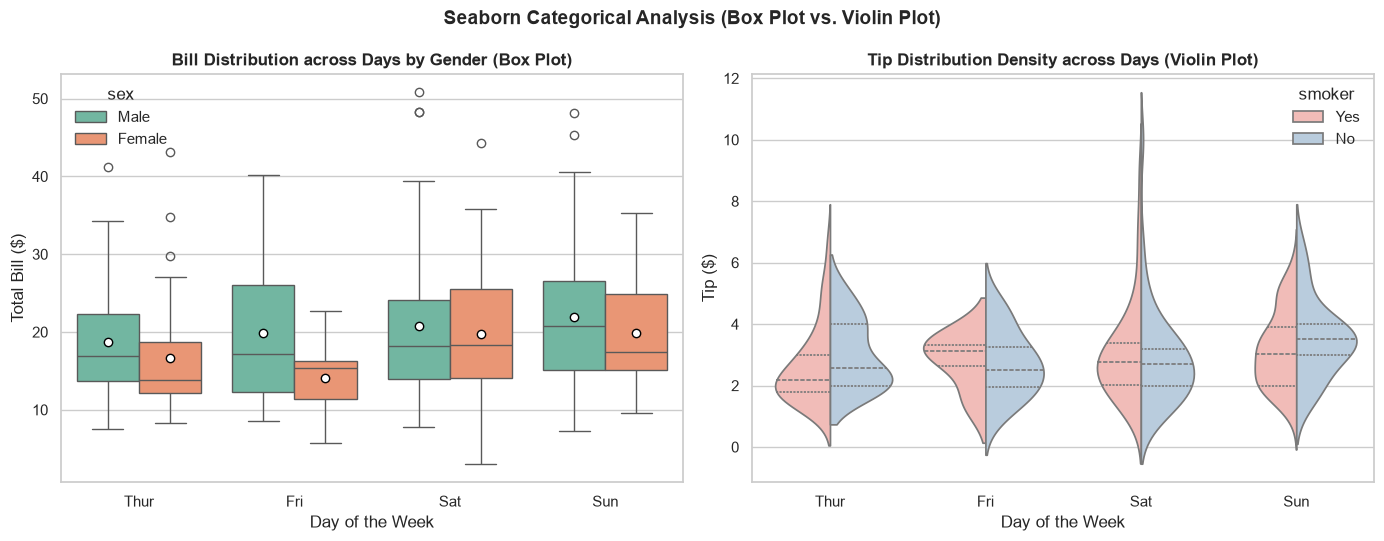

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=100)

# Boxplot
sns.boxplot(data=tips, x='day', y='total_bill', hue='sex', palette='Set2', showmeans=True,
            meanprops={"marker":"o","markerfacecolor":"white", "markeredgecolor":"black"}, ax=axes[0])
axes[0].set_title('Bill Distribution across Days by Gender (Box Plot)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Day of the Week')
axes[0].set_ylabel('Total Bill ($)')

# Violinplot
sns.violinplot(data=tips, x='day', y='tip', hue='smoker', split=True, inner='quart', palette='Pastel1', ax=axes[1])
axes[1].set_title('Tip Distribution Density across Days (Violin Plot)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Day of the Week')
axes[1].set_ylabel('Tip ($)')

plt.suptitle('Seaborn Categorical Analysis (Box Plot vs. Violin Plot)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
### 2.4 Statistical Aggregations: Barplot and Countplot
**Use Case:** Calculating group means with confidence interval error bars alongside discrete category observation counts.

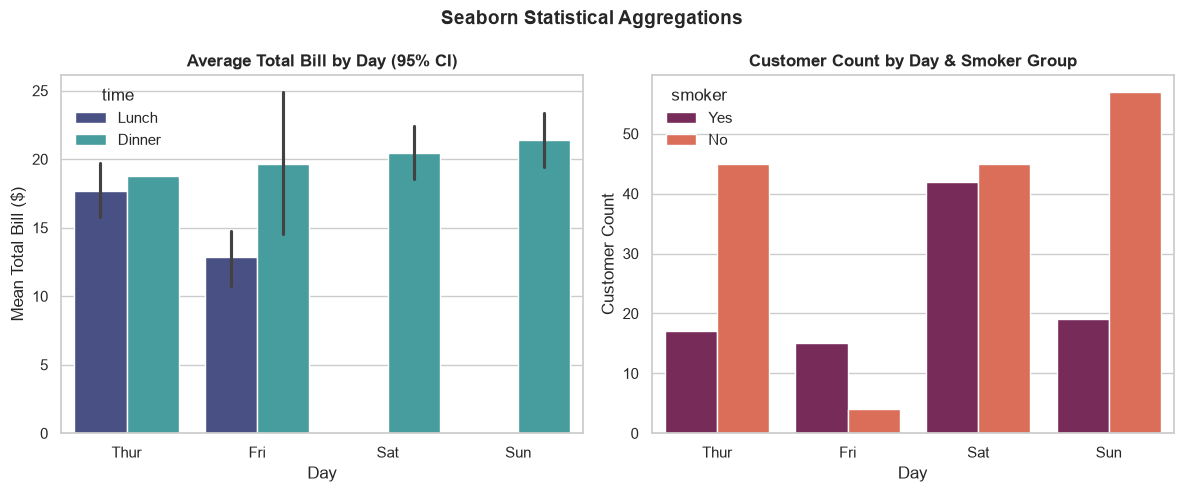

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=100)

sns.barplot(data=tips, x='day', y='total_bill', hue='time', errorbar=('ci', 95), palette='mako', ax=axes[0])
axes[0].set_title('Average Total Bill by Day (95% CI)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Day')
axes[0].set_ylabel('Mean Total Bill ($)')

sns.countplot(data=tips, x='day', hue='smoker', palette='rocket', ax=axes[1])
axes[1].set_title('Customer Count by Day & Smoker Group', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Customer Count')

plt.suptitle('Seaborn Statistical Aggregations', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
### 2.5 Distribution and Kernel Density Estimation (Histplot & KDE)
**Use Case:** Modeling continuous probability distributions, multimodal patterns, and comparative group distributions.

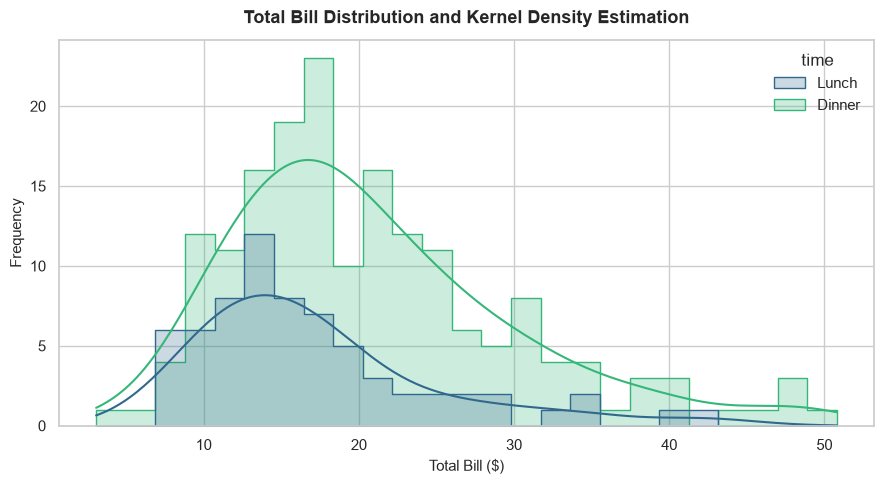

In [12]:
plt.figure(figsize=(9, 5), dpi=100)
sns.histplot(data=tips, x='total_bill', hue='time', kde=True, bins=25, palette='viridis', element='step')

plt.title('Total Bill Distribution and Kernel Density Estimation', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Total Bill ($)', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.tight_layout()
plt.show()

---
### 2.6 Correlation Matrix Heatmap
**Use Case:** Identifying linear collinearity and feature relationships across all numerical attributes simultaneously in tabular data.

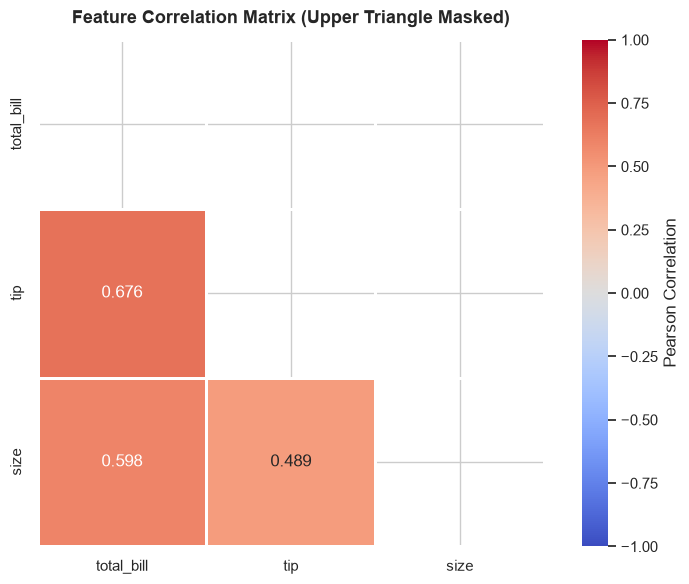

In [13]:
plt.figure(figsize=(8, 6), dpi=100)
numeric_df = tips.select_dtypes(include=[np.number])
corr = numeric_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, mask=mask,
            linewidths=1, square=True, cbar_kws={'label': 'Pearson Correlation'})

plt.title('Feature Correlation Matrix (Upper Triangle Masked)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

---
### 2.7 Multi-Feature Exploration: Pair Plot
**Use Case:** Comprehensive pairwise relationship matrix displaying univariate distributions along the diagonal and bivariate scatter plots on the off-diagonals.

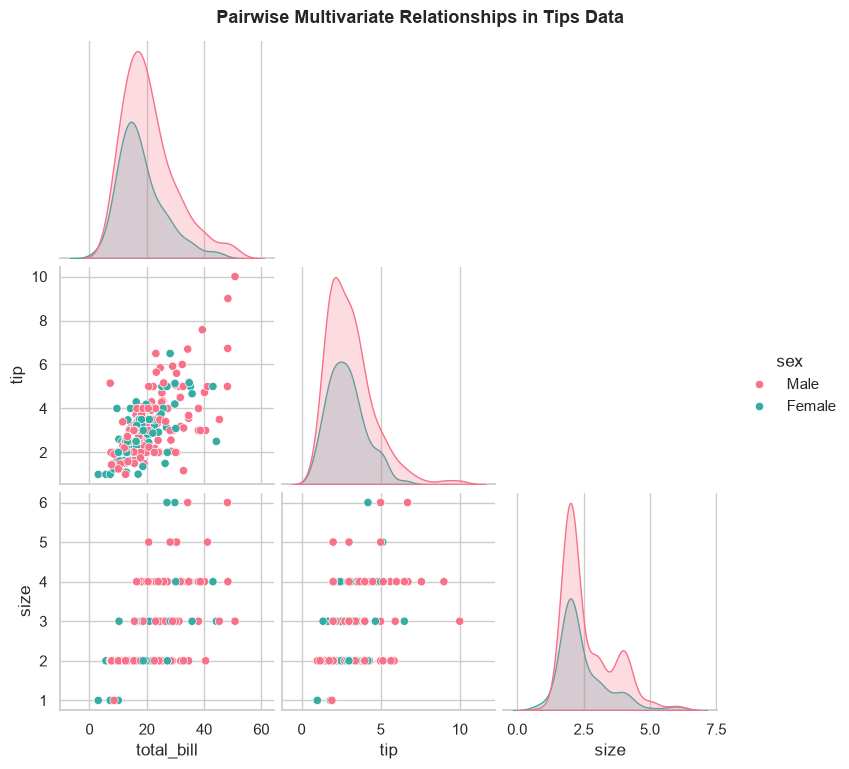

In [14]:
pair_fig = sns.pairplot(tips[['total_bill', 'tip', 'size', 'sex']], hue='sex', palette='husl', corner=True)
pair_fig.fig.suptitle('Pairwise Multivariate Relationships in Tips Data', y=1.02, fontsize=13, fontweight='bold')
plt.show()

---
# Section 3: Comparative Analysis (Matplotlib vs. Seaborn)

### 3.1 Side-by-Side Comparison Matrix

| Evaluation Dimension | Matplotlib | Seaborn |
| :--- | :--- | :--- |
| **API Philosophy** | Procedural & Object-Oriented low-level primitives | High-level, declarative, DataFrame-first syntax |
| **Ease of Use** | Requires explicit loops, axes positioning, and formatting code | One-line function calls with automatic statistical calculations |
| **Data Structure Compatibility** | Optimized for NumPy arrays, Python lists, and basic matrices | Built natively to consume tidy Pandas DataFrames |
| **Statistical Capabilities** | Manual calculation required for aggregations, CIs, regressions | Native computation of error bars, regression trends, and KDEs |
| **Styling & Aesthetics** | Plain default styling; requires manual color and font configuration | Beautiful, publication-ready default themes and color palettes |
| **Customization Depth** | Unlimited control over every pixel, tick, line, spine, and artist | Excellent for standard charts; relies on Matplotlib axes for fine edits |
| **Performance (Large Datasets)** | High speed when rendering raw arrays; scalable with collections | Slight computational overhead due to internal Pandas/stat transformations |
| **Primary Sweet Spot** | Custom dashboards, multi-panel figures, publication-specific tweaks | Fast exploratory data analysis (EDA) and statistical reporting |

---
### 3.2 Decision Framework: When to Use Which?

* **Use Matplotlib when:**
  * You need complete control over custom canvas layouts, canvas geometry, or non-standard diagrammatic charts.
  * You are rendering large-scale numeric arrays directly from NumPy without Pandas overhead.
  * You are developing specialized chart components or custom UI integrations.
  * You need to fine-tune individual axes spines, ticks, or artist layers.

* **Use Seaborn when:**
  * You are conducting Exploratory Data Analysis (EDA) on structured tabular DataFrames.
  * You need quick statistical summaries (e.g., automated 95% confidence intervals, violin density plots, correlation heatmaps).
  * You want to slice distributions across categorical dimensions using `hue`, `size`, and `style`.
  * You need aesthetic, cohesive, presentation-ready visualizations with minimal lines of code.

### 3.3 Best Practice Workflow: Synergistic Hybrid Usage
In professional data science workflows, Matplotlib and Seaborn are not mutually exclusive. The standard industry best practice is **hybrid usage**:
1. Initialize the figure structure and axes canvas using Matplotlib: `fig, ax = plt.subplots(...)`.
2. Generate complex statistical plots cleanly using Seaborn directed to the existing axes: `sns.barplot(..., ax=ax)`.
3. Apply fine-grained title adjustments, ticks, and layout polishing using Matplotlib: `ax.set_title(...)`, `plt.tight_layout()`.

---
## Conclusion
Both Matplotlib and Seaborn are indispensable tools in the Python data ecosystem. Mastering both equips a data scientist to rapidly explore complex datasets with Seaborn while retaining the granular power to customize any visual element with Matplotlib.